# Tomato CNN: an executed pipeline walkthrough

This notebook makes the existing project easier to explore in four stages: **data loading**, **cleaning and preprocessing**, **feature engineering**, and **model training**. It also recomputes the Pakistan external-test metrics from the saved prediction CSV.

**What has actually been run here:** loading repository records, preprocessing a clearly labelled synthetic image, checking duplicate fingerprints, running an untrained copy of the existing CNN to inspect tensor shapes, plotting historical training records, and recomputing saved prediction metrics. No new training or original-photo inference is claimed. The original datasets and manual audit inputs are not bundled, so full retraining is an explicit opt-in step at the end.

The notebook imports existing project functions and does not modify the Python scripts, checkpoints or frozen records. Saved outputs are included so you can read it directly on GitHub.

## Open and run

1. Clone **cnn-plant-disease-detection** and follow the [installation guide](README.md#installation-guide-windows--vs-code).
2. In the same virtual environment, install notebook support: `python -m pip install jupyterlab ipykernel`.
3. Run `python -m jupyterlab`, open `pipeline_walkthrough.ipynb` from the repository root, select that environment's Python kernel, then choose **Run All Cells**. VS Code with its Jupyter extension also works.

The default walkthrough works on CPU and does not download datasets. Dependencies for its calculations are already in [requirements.txt](requirements.txt). Optional training needs CUDA and the local inputs described in [Training reproduction](README.md#training-reproduction).

In [1]:
from pathlib import Path
import csv
import hashlib
import json
import platform
import sys
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import torch
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / 'model.py').is_file() and (ROOT.parent / 'model.py').is_file():
    ROOT = ROOT.parent
assert (ROOT / 'model.py').is_file(), 'Open this notebook from the cloned repository.'
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from model import LeafCNN, CLASSES
from prepare_data import fingerprint, ssim, CONFIG
from train import RECIPES, metrics, selection_score

def load_json(path):
    return json.loads((ROOT / path).read_text(encoding='utf-8'))

def show_table(headers, rows):
    def clean(value):
        return str(value).replace('|', '/').replace('\n', ' ')
    lines = ['| ' + ' | '.join(map(clean, headers)) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines += ['| ' + ' | '.join(map(clean, row)) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

torch.set_num_threads(2)
torch.manual_seed(20261022)
np.random.seed(20261022)
print('Python:', platform.python_version())
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
print('This walkthrough uses CPU; image size:', CONFIG['image_size'])

Python: 3.12.14
PyTorch: 2.11.0+cpu
CUDA available: False
This walkthrough uses CPU; image size: 160


## 1. Data loading

The actual preparation entry point is [prepare_data.py](prepare_data.py). It loads the audited PlantVillage, Bangladesh, whole-leaf TLID and tomato-only PlantDoc manifests from configured local source projects. Existing test partitions are preserved; development fold 1 supplies validation. Additional stages use [prepare_field.py](prepare_field.py), [prepare_zenodo.py](prepare_zenodo.py), and [prepare_plantwild.py](prepare_plantwild.py).

Since the raw datasets are not bundled, this runnable example loads the **included, frozen experiment records**. The following table shows recorded evaluation cohort sizes, not newly loaded training photos. The nine rows include seven training-source holdouts plus two small illustrative checks. Source details and labels are in [EXPERIMENT_PROTOCOL.md](EXPERIMENT_PROTOCOL.md).

In [2]:
final_metrics = load_json('evaluation_final/metrics.json')
show_table(['Recorded cohort', 'Evaluation examples', 'Accuracy', 'Balanced accuracy'], [
    [name, result['n'], f"{result['accuracy']:.2%}", f"{result['balanced_accuracy']:.2%}"]
    for name, result in sorted(final_metrics.items())
])
print('Model classes:', dict(enumerate(CLASSES)))
print('Raw training photos are local inputs, not part of this walkthrough.')

Model classes: {0: 'Healthy', 1: 'Unhealthy'}
Raw training photos are local inputs, not part of this walkthrough.


| Recorded cohort | Evaluation examples | Accuracy | Balanced accuracy |
| --- | --- | --- | --- |
| Bangladesh | 139 | 87.77% | 86.04% |
| GTLD_examples | 7 | 85.71% | 91.67% |
| Internet16 | 16 | 81.25% | 81.25% |
| PlantDoc | 69 | 86.96% | 78.33% |
| PlantVillage | 3632 | 94.47% | 96.97% |
| PlantWild | 433 | 90.99% | 88.01% |
| TLID | 3050 | 92.59% | 94.48% |
| TomatoDisease_ROI | 488 | 93.85% | 93.62% |
| TomatoVillage | 1764 | 95.98% | 97.96% |

## 2. Cleaning and preprocessing

The real pipeline checks file hashes, corrects EXIF orientation, converts images to RGB, resizes to **160 × 160** with bilinear interpolation, and stores channel-first uint8 arrays. Normalization at model input is `x / 127.5 - 1`. See [prepare_data.py](prepare_data.py) and [predict.py](predict.py).

This cell uses a **synthetic colour pattern** only to show the transformations without downloading or redistributing dataset photos. It has no Healthy/Unhealthy reference label and is not used to measure model accuracy. Set `DEMO_IMAGE` to a local image path to inspect your own image instead; keep it `None` to reproduce the saved demonstration.

Original size (width, height): (320, 240)
Cached array: (3, 160, 160) uint8
Model input: (1, 3, 160, 160) torch.float32
Normalized range: -1.0 to 0.992


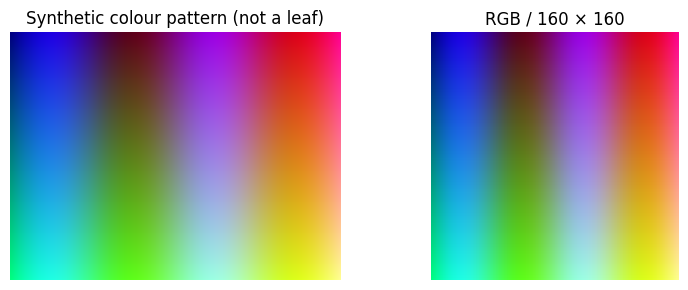

In [3]:
DEMO_IMAGE = None  # Example: 'my_tomato_leaf.jpg'
if DEMO_IMAGE is None:
    yy, xx = np.mgrid[0:240, 0:320]
    rgb = np.stack([xx * 255 / 319, yy * 255 / 239,
                    127 + 100 * np.sin(xx / 25)], axis=-1)
    original = Image.fromarray(np.clip(rgb, 0, 255).astype(np.uint8))
    example_label = 'Synthetic colour pattern (not a leaf)'
else:
    with Image.open(Path(DEMO_IMAGE).expanduser()) as opened:
        original = ImageOps.exif_transpose(opened).convert('RGB').copy()
    example_label = 'Your local input image'

prepared = ImageOps.exif_transpose(original).convert('RGB').resize(
    (CONFIG['image_size'], CONFIG['image_size']), Image.Resampling.BILINEAR)
pixels = np.asarray(prepared).copy().transpose(2, 0, 1)
tensor = torch.from_numpy(pixels).unsqueeze(0).float() / 127.5 - 1
assert pixels.shape == (3, 160, 160)
assert tensor.shape == (1, 3, 160, 160)
assert float(tensor.min()) >= -1 and float(tensor.max()) <= 1
print('Original size (width, height):', original.size)
print('Cached array:', pixels.shape, pixels.dtype)
print('Model input:', tuple(tensor.shape), tensor.dtype)
print('Normalized range:', round(float(tensor.min()), 3), 'to', round(float(tensor.max()), 3))
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(original); axes[0].set_title(example_label)
axes[1].imshow(prepared); axes[1].set_title('RGB / 160 × 160')
for ax in axes: ax.axis('off')
fig.tight_layout()
plt.show()

### Duplicate checks and split protection

The existing audit combines original groups, decoded-pixel hashes and perceptual-hash candidates (Hamming distance ≤ 4), confirmed with block SSIM ≥ 0.97. A related group stays in one split, with **test > validation > train** priority. Conflicting labels on identical pixels cause exclusion. New-source overlap exclusions and region-specific rules are documented in the [README pipeline](README.md#2-cleaning-and-preprocessing).

Below we call the existing fingerprint and SSIM helpers on two identical copies. This checks the helper behaviour; it does not claim to rerun the full dataset audit or prove independence between photos.

In [4]:
copy_image = prepared.copy()
phash_a, thumb_a = fingerprint(prepared)
phash_b, thumb_b = fingerprint(copy_image)
pixel_hash_a = hashlib.sha256(prepared.tobytes()).hexdigest()
pixel_hash_b = hashlib.sha256(copy_image.tobytes()).hexdigest()
hamming = (phash_a ^ phash_b).bit_count()
similarity = ssim(thumb_a, thumb_b)
assert pixel_hash_a == pixel_hash_b
assert hamming == 0 and abs(similarity - 1.0) < 1e-6
show_table(['Check on identical copies', 'Observed value'], [
    ['Decoded-pixel SHA-256 matches', pixel_hash_a == pixel_hash_b],
    ['Perceptual-hash Hamming distance', hamming],
    ['Block SSIM', f'{similarity:.6f}'],
    ['Near-duplicate rule met', hamming <= 4 and similarity >= 0.97]
])

| Check on identical copies | Observed value |
| --- | --- |
| Decoded-pixel SHA-256 matches | True |
| Perceptual-hash Hamming distance | 0 |
| Block SSIM | 1.000000 |
| Near-duplicate rule met | True |

## 3. Feature engineering

The CNN learns image features jointly with its classifier. It has four convolutional stages with 32, 64, 128 and 192 channels; the selected architecture adds channel attention. Adaptive 2 × 2 pooling gives 768 features for the dense classifier. Duplicate-audit hashes are **not** classifier features. See [model.py](model.py).

This cell instantiates the existing architecture and runs a CPU forward pass to show tensor shapes. **Its weights are randomly initialized**, so this is an architecture demonstration, not a prediction from the delivered trained model. No probabilities or accuracy are attributed to this random network.

In [5]:
demo_model = LeafCNN(attention=True).cpu().eval()
shapes = []
handles = []
for name, layer in demo_model.named_modules():
    if isinstance(layer, (torch.nn.MaxPool2d, torch.nn.AdaptiveAvgPool2d, torch.nn.Linear)):
        def record_shape(module, inputs, output, layer_name=name):
            shapes.append([layer_name, module.__class__.__name__, tuple(output.shape)])
        handles.append(layer.register_forward_hook(record_shape))
try:
    with torch.inference_mode():
        demo_logits = demo_model(tensor.cpu())
finally:
    for handle in handles: handle.remove()
parameter_count = sum(p.numel() for p in demo_model.parameters())
assert demo_logits.shape == (1, 2)
assert parameter_count == 955194
assert torch.isfinite(demo_logits).all()
print(f'Parameters: {parameter_count:,}; output shape: {tuple(demo_logits.shape)}')
show_table(['Layer', 'Operation', 'Output tensor shape'], shapes)

Parameters: 955,194; output shape: (1, 2)


| Layer | Operation | Output tensor shape |
| --- | --- | --- |
| features.6.gate.0 | AdaptiveAvgPool2d | (1, 32, 1, 1) |
| features.7 | MaxPool2d | (1, 32, 80, 80) |
| features.14.gate.0 | AdaptiveAvgPool2d | (1, 64, 1, 1) |
| features.15 | MaxPool2d | (1, 64, 40, 40) |
| features.22.gate.0 | AdaptiveAvgPool2d | (1, 128, 1, 1) |
| features.23 | MaxPool2d | (1, 128, 20, 20) |
| features.30.gate.0 | AdaptiveAvgPool2d | (1, 192, 1, 1) |
| features.31 | MaxPool2d | (1, 192, 10, 10) |
| classifier.0 | AdaptiveAvgPool2d | (1, 192, 2, 2) |
| classifier.2 | Linear | (1, 128) |
| classifier.5 | Linear | (1, 2) |

## 4. Model training

[train.py](train.py) implements the existing recipes, balanced source × class sampling, AdamW, augmentation, label smoothing, learning-rate scheduling and validation-only checkpoint selection. The score is `0.6 × mean source balanced accuracy + 0.4 × minimum source balanced accuracy`; the prediction threshold stays at 0.5.

Stage A compares three recipes from random weights. [Stage B](train_field.py) retrains the selected recipe from random weights with Tomato-Village; [stage C](train_extra.py) and [stage D](train_wild.py) continue this project's checkpoints with all-source replay. No externally pretrained model is used.

The cells below **read the historical training records**; they do not run training again. The chart shows the recorded stage-D loss and validation progress.

In [6]:
show_table(['Initial recipe', 'Strong augmentation', 'Channel attention', 'Mixup alpha', 'Base learning rate'], [
    [name, recipe['strong'], recipe['attention'], recipe['mixup'], recipe['lr']]
    for name, recipe in RECIPES.items()
])
run_names = ['mixed_mild_v1', 'mixed_strong_v1', 'mixed_attention_v1',
             'mixed_attention_field_v1', 'mixed_attention_extra_v1', 'mixed_attention_wild_v1']
run_rows = []
for name in run_names:
    completed = load_json(f'runs/{name}/complete.json')
    config = load_json(f'runs/{name}/configuration.json')
    run_rows.append([name, completed['epochs_run'], completed['best_epoch'],
                     config['batch_size'], f"{completed['best_validation_score']:.4f}"])
show_table(['Saved run', 'Epochs run', 'Selected epoch', 'Batch size', 'Own validation score'], run_rows)
print("Scores use each stage's own validation sources; they are not matched-cohort comparisons.")

Scores use each stage's own validation sources; they are not matched-cohort comparisons.


| Initial recipe | Strong augmentation | Channel attention | Mixup alpha | Base learning rate |
| --- | --- | --- | --- | --- |
| mixed_mild | False | False | 0.0 | 0.001 |
| mixed_strong | True | False | 0.15 | 0.001 |
| mixed_attention | True | True | 0.1 | 0.0007 |

| Saved run | Epochs run | Selected epoch | Batch size | Own validation score |
| --- | --- | --- | --- | --- |
| mixed_mild_v1 | 30 | 22 | 96 | 0.8246 |
| mixed_strong_v1 | 30 | 25 | 96 | 0.8243 |
| mixed_attention_v1 | 30 | 26 | 96 | 0.8345 |
| mixed_attention_field_v1 | 40 | 37 | 100 | 0.8669 |
| mixed_attention_extra_v1 | 20 | 7 | 96 | 0.8499 |
| mixed_attention_wild_v1 | 25 | 17 | 112 | 0.8659 |

Recomputed every saved stage-D selection score successfully.


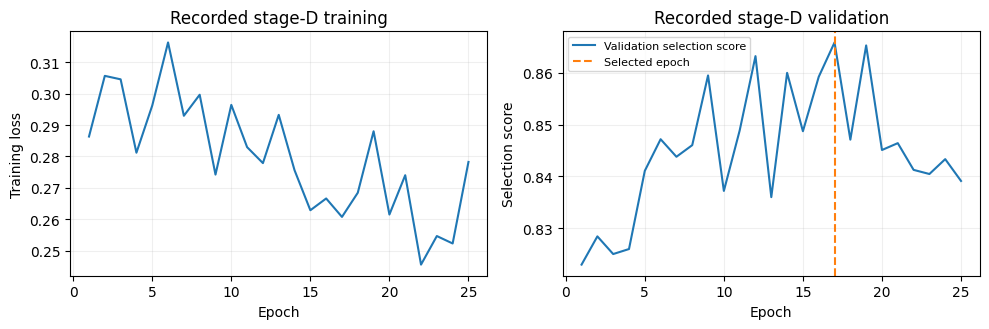

In [7]:
history = load_json('runs/mixed_attention_wild_v1/history.json')
completed = load_json('runs/mixed_attention_wild_v1/complete.json')
for epoch in history:
    assert abs(selection_score(epoch['validation']) - epoch['selection_score']) < 1e-10
epochs = [r['epoch'] for r in history]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(epochs, [r['training_loss'] for r in history])
axes[0].set(xlabel='Epoch', ylabel='Training loss', title='Recorded stage-D training')
axes[1].plot(epochs, [r['selection_score'] for r in history], label='Validation selection score')
axes[1].axvline(completed['best_epoch'], color='tab:orange', linestyle='--', label='Selected epoch')
axes[1].set(xlabel='Epoch', ylabel='Selection score', title='Recorded stage-D validation')
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
print('Recomputed every saved stage-D selection score successfully.')

## Check the saved external-test predictions

The Pakistan evaluation uses the unchanged delivered checkpoint at threshold 0.5. We load the committed [prediction CSV](evaluation_unseen_matching/predictions.csv), call the project's existing `metrics()` function and compare all six scalar metrics and the confusion matrix with [metrics.json](evaluation_unseen_matching/metrics.json). This reruns the **metric calculation**, not model inference, source eligibility auditing or hash verification of original images.

The disease-category names below remain publisher reference categories. The model makes binary Healthy/Unhealthy decisions, not disease-name predictions. See the [external-test report](evaluation_unseen_matching/REPORT.md).

In [8]:
with (ROOT / 'evaluation_unseen_matching/predictions.csv').open(encoding='utf-8-sig', newline='') as file:
    predictions = list(csv.DictReader(file))
labels = np.array([int(r['label']) for r in predictions])
probabilities = np.array([float(r['probability_unhealthy']) for r in predictions])
assert np.isfinite(probabilities).all() and ((probabilities >= 0) & (probabilities <= 1)).all()
recomputed = metrics(labels, probabilities)
recorded = load_json('evaluation_unseen_matching/metrics.json')
keys = ['n', 'accuracy', 'balanced_accuracy', 'macro_f1', 'healthy_recall', 'unhealthy_recall']
for key in keys:
    assert abs(recomputed[key] - recorded[key]) < 1e-10, key
assert recomputed['confusion_matrix'] == recorded['confusion_matrix']
assert len(predictions) == 461
show_table(['Metric', 'Recomputed value'], [
    [key, str(recomputed[key]) if key == 'n' else f'{recomputed[key]:.2%}'] for key in keys
])
correct = (probabilities >= 0.5) == labels
print(f'All checked metrics match the saved records: {int(correct.sum())}/{len(labels)} correct.')
categories = sorted({r['category'] for r in predictions})
show_table(['Publisher category', 'Tested', 'Correct binary decisions'], [
    [category, sum(r['category'] == category for r in predictions),
     sum(bool(ok) for r, ok in zip(predictions, correct) if r['category'] == category)]
    for category in categories
])

All checked metrics match the saved records: 408/461 correct.


| Metric | Recomputed value |
| --- | --- |
| n | 461 |
| accuracy | 88.50% |
| balanced_accuracy | 85.37% |
| macro_f1 | 84.87% |
| healthy_recall | 79.13% |
| unhealthy_recall | 91.62% |

| Publisher category | Tested | Correct binary decisions |
| --- | --- | --- |
| Early blight | 76 | 68 |
| Healthy | 115 | 91 |
| Late blight | 30 | 26 |
| Leaf mold | 146 | 146 |
| Septoria leaf spot | 61 | 60 |
| Yellow leaf curl virus | 33 | 17 |

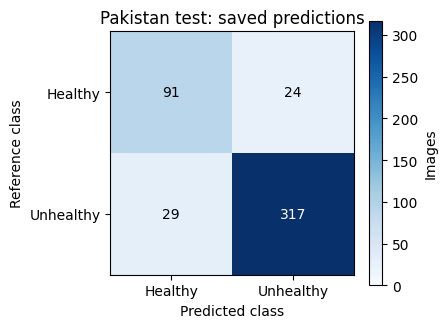

In [9]:
cm = np.array(recomputed['confusion_matrix'])
fig, ax = plt.subplots(figsize=(4.5, 3.6))
image = ax.imshow(cm, cmap='Blues', vmin=0)
for row in range(2):
    for col in range(2):
        ax.text(col, row, str(cm[row, col]), ha='center', va='center',
                color='white' if cm[row, col] > cm.max() / 2 else 'black')
ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=CLASSES, yticklabels=CLASSES,
       xlabel='Predicted class', ylabel='Reference class', title='Pakistan test: saved predictions')
fig.colorbar(image, ax=ax, label='Images')
fig.tight_layout()
plt.show()

## Optional: train or predict using the existing scripts

Full training is deliberately disabled by default. Before enabling it, restore the original datasets, audited manifests and saved PlantWild review decisions; configure `local_config.json`; install CUDA-enabled PyTorch; and follow the complete [reproduction sequence](README.md#training-reproduction). Do not use the synthetic image above as training data. Existing completed run names and frozen outputs must remain protected.

The opt-in cell below demonstrates a **new stage-A run only**, using a separate run suffix and selection record. Stages B–D require the corresponding data preparation and training scripts described above. The cell is not evidence of a new trained model until you enable it and successfully complete training.

In [10]:
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    import subprocess
    assert torch.cuda.is_available(), 'Full training requires CUDA.'
    assert (ROOT / 'data/manifest.csv').is_file(), 'Restore audited data inputs first.'
    new_run = ROOT / 'runs/mixed_attention_notebook_demo'
    new_selection = ROOT / 'runs/selection_notebook_demo.json'
    assert not new_run.exists() and not new_selection.exists(), 'Choose a fresh run suffix and selection filename.'
    subprocess.run([
        sys.executable, str(ROOT / 'train.py'), '--recipes', 'mixed_attention',
        '--epochs', '30', '--steps', '64', '--suffix', '_notebook_demo',
        '--selection', 'selection_notebook_demo.json'
    ], cwd=ROOT, check=True)
else:
    print('Optional training is disabled. No training files or checkpoints were changed.')

Optional training is disabled. No training files or checkpoints were changed.


For a prediction with the **delivered trained model**, use your own close-up tomato-leaf photograph and the existing script from a terminal:

```powershell
python predict.py "C:\path\to\tomato_leaf.jpg"
```

The delivered checkpoint is `best_model.pt`; see [MODEL_CARD.md](MODEL_CARD.md) before interpreting its output. The synthetic forward pass in this notebook is not a trained-model prediction. Scores are uncalibrated and the model does not verify plant species.

## Interpretation and limitations

- High performance on a source-specific holdout does not establish arbitrary internet accuracy.
- Duplicate checks reduce known overlap but cannot prove plant/session independence.
- Healthy references may mean apparently asymptomatic foliage rather than a verified biological diagnosis.
- Saved training curves describe historical runs; the notebook does not silently repeat those experiments.
- Original data, caches and frozen audit inputs are needed for fresh training and dataset-level reproduction.

Continue with [the full protocol](EXPERIMENT_PROTOCOL.md), [results](RESULTS.md), [the model card](MODEL_CARD.md), or [the detailed file guide](README.md#detailed-file-guide).